# L1-b · Last-direction baseline

Repeat the direction from the previous observed fixing to the current fixing: `sign(log(J_t / J_prev))`. UP = USD/IDR rises (IDR depreciates). For a flat or missing latest return, use the training UP prior; ties predict UP. The fallback stays fixed within each evaluation period.

Use the [shared split](../../SPLIT_PROTOCOL.md) and [ablation protocol](../../rules/ablation_protocol.md). Run all cells. Dependencies: NumPy, pandas, Matplotlib. Outputs stay inside this notebook.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "L1-b"
RUN_FINAL_TEST = False  # Enable only after the experiment configurations are frozen.
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10       # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

L1-b | final test enabled: False
Python 3.14.4 | pandas 2.3.3 | NumPy 2.3.5 | Matplotlib 3.10.7+dfsg1


## Shared data

Load the same dates and labels as L1-a. Read `log_return_t` from the full fixing calendar, including FLAT/warmup rows; `return_lag1` is one fixing older. At each decision, the current fixing is observed. Earlier validation prices may inform later decisions; validation labels never fit the fallback. News metadata is for reporting only.

In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert daily.Date.is_monotonic_increasing
observed_return = np.log(daily.USD_IDR / daily.USD_IDR.shift(1))
assert np.allclose(daily.log_return_t, observed_return, rtol=1e-10, atol=1e-12, equal_nan=True)
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", "log_return_t"]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_validation_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    assert train.target_date.max() < val.Date.min()
    assert not set(train.Date) & set(val.Date)
    assert not seen_validation_dates & set(val.Date)
    seen_validation_dates.update(val.Date)
    for role, frame in [("train", train), ("validation", val)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})
final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")

,run,role,n,first,last,down,up,news_days
0,fold_1,train,453,2021-09-29,2023-08-15,193,260,65
1,fold_1,validation,158,2023-08-21,2024-04-19,64,94,21
2,fold_2,train,612,2021-09-29,2024-04-19,257,355,86
3,fold_2,validation,159,2024-04-23,2024-12-12,78,81,32
4,fold_3,train,772,2021-09-29,2024-12-12,335,437,118
5,fold_3,validation,158,2024-12-16,2025-08-26,79,79,22


Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions


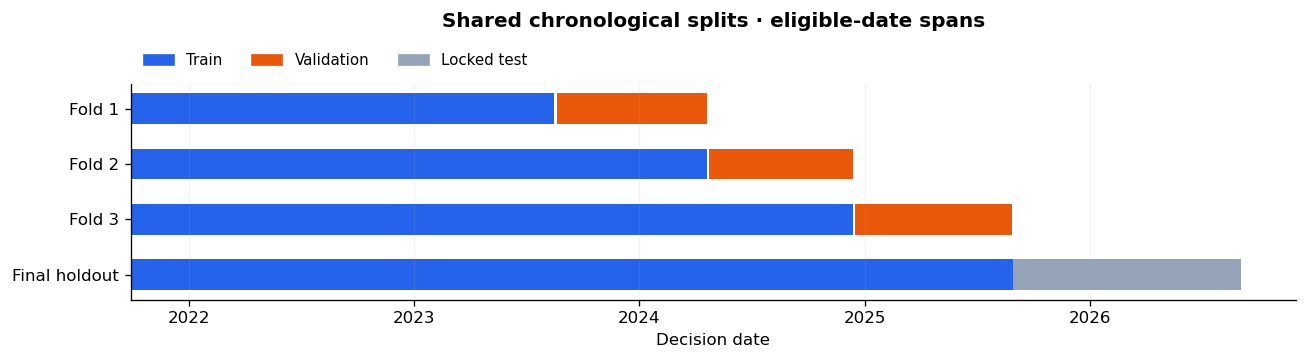

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.1))
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1])]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        left = mdates.date2num(dates.min())
        width = mdates.date2num(dates.max()) - left + 1
        ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · eligible-date spans", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train"), Patch(color=COLORS[1], label="Validation"),
                   Patch(color="#94a3b8", label="Locked test")], loc="lower left", bbox_to_anchor=(0, 1.01),
          ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()

## Baseline and metrics

Positive last return → UP; negative → DOWN; zero/missing → training-majority fallback. The model is deterministic and needs no training-seed repetitions.

Primary: **MCC**. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin equal-width ECE. Metrics match L1-a. Undefined precision/F1 uses zero; single-class actual subsets have undefined MCC, balanced accuracy, and AUC.

Direction probabilities are hard 0/1 scores, except for fallback rows. They are uncalibrated. Log loss clips probabilities to `[1e-15, 1-1e-15]`; confident errors therefore incur large losses. No probability calibration is fitted.

In [4]:
def fit_majority(y):
    y = np.asarray(y, dtype=int)
    assert len(y) and np.isin(y, [0, 1]).all()
    p_up = float(y.mean())
    return {"p_up": p_up, "majority": int(p_up >= .5)}

def momentum_probability(last_return, fallback_p_up):
    last_return = np.asarray(last_return, dtype=float)
    assert not np.isinf(last_return).any()
    assert 0 <= fallback_p_up <= 1
    return np.where(last_return > 0, 1., np.where(last_return < 0, 0., fallback_p_up))

def score_binary(y, probability):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= .5).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up,
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
assert fit_majority([0, 1])["majority"] == 1
assert np.array_equal(momentum_probability([-.1, 0, .2, np.nan], .6), [0., .6, 1., .6])
assert np.array_equal(momentum_probability([-.1, 0, .2, np.nan], .4) >= .5, [False, False, True, False])
prices = pd.Series([100., 110., 99., 99., 108.])
returns = np.log(prices / prices.shift(1))
assert np.array_equal(momentum_probability(returns, .6) >= .5, [True, True, False, True, True])
changed_future = pd.Series([100., 110., 99., 198., 194.])
changed_return = np.log(changed_future / changed_future.shift(1))
assert np.array_equal(momentum_probability(returns, .6)[:3], momentum_probability(changed_return, .6)[:3])
print("Metric, direction, fallback, and causal-prefix checks passed.")

Metric, direction, fallback, and causal-prefix checks passed.


In [5]:
predictions_list, result_rows, fit_rows = [], [], []

def evaluate_run(run, train, evaluation, role):
    start = time.perf_counter()
    fitted = fit_majority(train.y)
    fit_ms = (time.perf_counter() - start) * 1000
    start = time.perf_counter()
    last_return = evaluation.log_return_t.to_numpy(dtype=float)
    probability = momentum_probability(last_return, fitted["p_up"])
    predicted = (probability >= .5).astype(int)
    fallback = (last_return == 0) | np.isnan(last_return)
    predict_ms = (time.perf_counter() - start) * 1000
    assert np.array_equal(predicted[last_return > 0], np.ones(np.sum(last_return > 0), dtype=int))
    assert np.array_equal(predicted[last_return < 0], np.zeros(np.sum(last_return < 0), dtype=int))
    scored = score_binary(evaluation.y, probability)
    result_rows.append({"run": run, "role": role, **scored})
    fit_rows.append({"run": run, "train_n": len(train), "train_down": int(train.y.eq(0).sum()),
                     "train_up": int(train.y.eq(1).sum()), "fallback_p_up": fitted["p_up"],
                     "fallback_majority": LABELS[fitted["majority"]], "fallback_n": int(fallback.sum()),
                     "flat_return_n": int(np.sum(last_return == 0)), "missing_return_n": int(np.isnan(last_return).sum()),
                     "fit_ms": fit_ms, "predict_ms": predict_ms,
                     "trainable_parameters": 0, "estimated_prior_parameters": 1})
    columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days", "log_return_t"]
    output = evaluation[columns].copy()
    output["run"], output["role"], output["model_id"] = run, role, MODEL_ID
    output["p_up"], output["y_pred"], output["training_seed"] = probability, predicted, None
    output["used_fallback"] = fallback
    output["direction_source"] = np.select([last_return > 0, last_return < 0, last_return == 0],
                                          ["repeat_UP", "repeat_DOWN", "flat_train_prior"], default="missing_train_prior")
    assert output.Date.tolist() == evaluation.Date.tolist()
    predictions_list.append(output)

for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    evaluate_run(f"fold_{fold_id}", train, val, "validation")

if RUN_FINAL_TEST:
    test = take_rows(final.loc[final.role.eq("test")])
    evaluate_run("final_test", final_train, test, "test")

predictions = pd.concat(predictions_list, ignore_index=True)
results = pd.DataFrame(result_rows)
fits = pd.DataFrame(fit_rows)
assert not predictions.duplicated(["role", "Date"]).any()
assert len(predictions.loc[predictions.role.eq("validation")]) == len(seen_validation_dates)
display(fits.round(5))
display(results[["run", "role", "n", *METRICS]].round(4))
validation_results = results.loc[results.role.eq("validation"), METRICS]
display(pd.DataFrame({"mean_validation": validation_results.mean(),
                      "std_across_folds": validation_results.std(ddof=1)}).round(4))
print("Fold standard deviation measures period variation, not a confidence interval.")
print("Final test scored." if RUN_FINAL_TEST else "Final-test scoring remains locked.")

,run,train_n,train_down,train_up,fallback_p_up,fallback_majority,fallback_n,flat_return_n,missing_return_n,fit_ms,predict_ms,trainable_parameters,estimated_prior_parameters
0,fold_1,453,193,260,0.57395,UP,1,1,0,0.07838,0.03937,0,1
1,fold_2,612,257,355,0.58007,UP,0,0,0,0.08204,0.04475,0,1
2,fold_3,772,335,437,0.56606,UP,1,1,0,0.08302,0.03741,0,1


,run,role,n,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
0,fold_1,validation,158,0.0653,0.5326,0.5326,0.5506,0.5296,0.4505,15.5243,0.4521
1,fold_2,validation,159,0.0940,0.5470,0.5470,0.5472,0.5470,0.4528,15.6404,0.4528
2,fold_3,validation,158,0.0253,0.5126,0.5127,0.5127,0.5159,0.4830,16.6191,0.4846


,mean_validation,std_across_folds
mcc,0.0616,0.0345
macro_f1,0.5308,0.0173
balanced_accuracy,0.5307,0.0172
accuracy,0.5368,0.0210
roc_auc,0.5308,0.0156
brier,0.4621,0.0181
log_loss,15.9279,0.6014
ece_10,0.4632,0.0186


Fold standard deviation measures period variation, not a confidence interval.
Final-test scoring remains locked.


## Sampling uncertainty

95% percentile intervals: 1,000 circular moving-block resamples, block length 10 evaluated observations, seed `20261110 + run index`. Predictions remain fixed; intervals measure evaluation-sample uncertainty, not training uncertainty. Reuse the same ordered dates, block settings, and seeds for future paired model comparisons. No model-difference claim is made here.

In [6]:
def block_intervals(frame, seed):
    frame = frame.sort_values("Date")
    y, probability = frame.y.to_numpy(dtype=int), frame.p_up.to_numpy(dtype=float)
    n = len(frame)
    rng = np.random.default_rng(seed)
    sampled = {metric: [] for metric in METRICS}
    length = min(BLOCK_LENGTH, n)
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        score = score_binary(y[positions], probability[positions])
        for metric in METRICS:
            sampled[metric].append(score[metric])
    intervals = []
    for metric, values in sampled.items():
        values = np.asarray(values, dtype=float)
        valid = values[np.isfinite(values)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        intervals.append({"metric": metric, "low_95": float(low), "high_95": float(high),
                          "valid_resamples": len(valid)})
    return intervals

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))

,run,metric,low_95,high_95,valid_resamples
0,fold_1,mcc,-0.0689,0.1757,1000
1,fold_1,macro_f1,0.4653,0.5878,1000
2,fold_1,balanced_accuracy,0.4662,0.5879,1000
3,fold_1,accuracy,0.4873,0.6139,1000
8,fold_2,mcc,-0.0200,0.1949,1000
9,fold_2,macro_f1,0.4898,0.5971,1000
10,fold_2,balanced_accuracy,0.4900,0.5973,1000
11,fold_2,accuracy,0.4906,0.6038,1000
16,fold_3,mcc,-0.0888,0.1350,1000
17,fold_3,macro_f1,0.4553,0.5672,1000


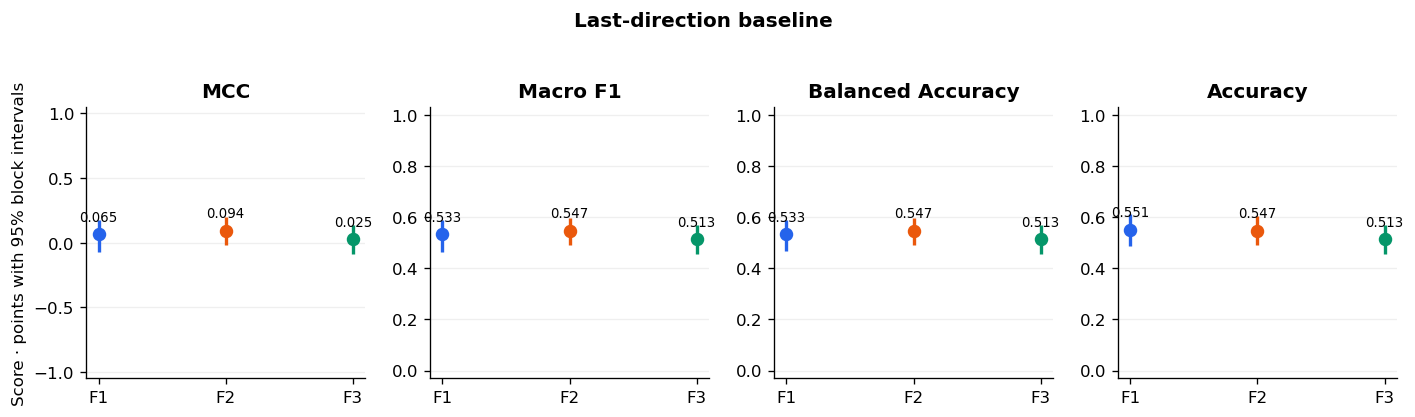

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("Last-direction baseline", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()

## Classes, confusion, and probability quality

Confusion matrices use actual rows and predicted columns; annotations show counts and row percentages. Calibration shows occupied bins only. Hard scores do not imply certainty about the next fixing; inspect probability losses alongside classification scores. Small fallback bins have high sampling uncertainty.

,run,class,support,precision,recall,f1
0,fold_1,DOWN,64,0.4444,0.4375,0.4409
1,fold_1,UP,94,0.6211,0.6277,0.6243
2,fold_2,DOWN,78,0.5385,0.5385,0.5385
3,fold_2,UP,81,0.5556,0.5556,0.5556
4,fold_3,DOWN,79,0.5128,0.5063,0.5096
5,fold_3,UP,79,0.5125,0.5190,0.5157


,run,bin,n,predicted_up,observed_up
0,fold_1,0,63,0.0000,0.5556
1,fold_1,5,1,0.5740,1.0000
2,fold_1,9,94,1.0000,0.6170
3,fold_2,0,78,0.0000,0.4615
4,fold_2,9,81,1.0000,0.5556
5,fold_3,0,78,0.0000,0.4872
6,fold_3,5,1,0.5661,0.0000
7,fold_3,9,79,1.0000,0.5190


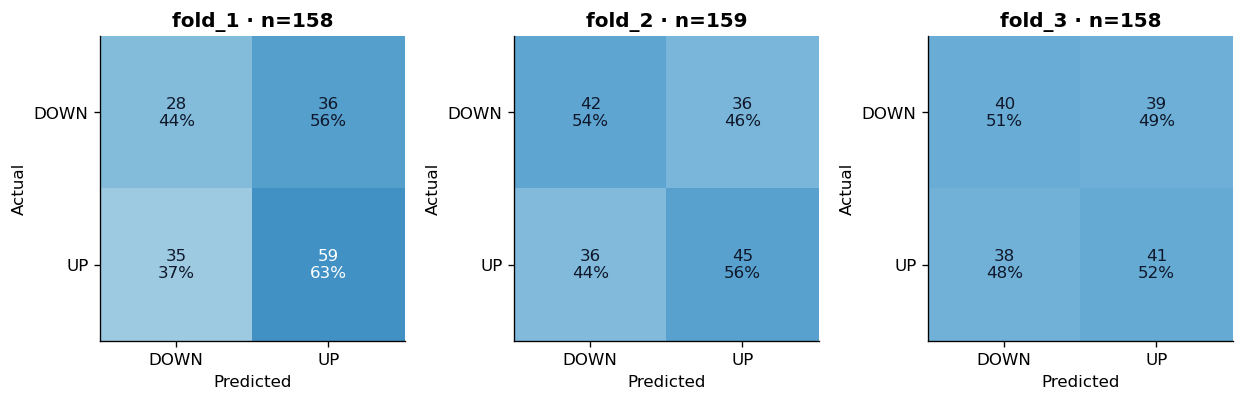

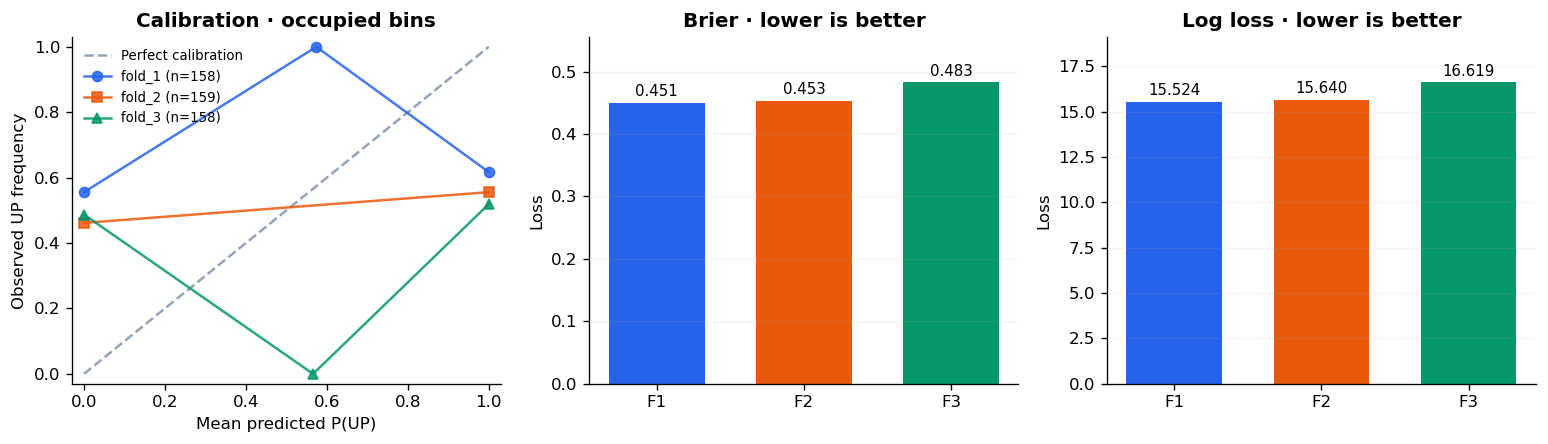

In [8]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"],
                           "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "n": len(group),
                                 "predicted_up": float(group.p_up.mean()), "observed_up": float(group.y.mean())})
per_class = pd.DataFrame(class_rows)
calibration = pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · n={row['n']}")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=f"{run} (n={frame.n.sum()})")
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)", ylabel="Observed UP frequency", title="Calibration · occupied bins")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Brier · lower is better"),
                           (axes[2], "log_loss", "Log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()

## Coverage and subgroup checks

Keep all eligible dates. Report news-present, empty, singleton, and multi-article windows separately. Weekday/gap groups use the **target endpoint**, so Friday→Monday belongs to target Monday. These are descriptive checks; small subsets are not evidence of an effect.

,run,group,n,mcc,macro_f1,balanced_accuracy,accuracy
0,fold_1,all,158,0.0653,0.5326,0.5326,0.5506
1,fold_1,news_present,21,0.1132,0.5553,0.5556,0.5714
2,fold_1,empty,137,0.0583,0.5292,0.5292,0.5474
3,fold_1,singleton,13,0.5007,0.7451,0.7375,0.7692
4,fold_1,multi_article,8,-0.5000,0.2500,0.2500,0.2500
5,fold_1,target_Monday,30,-0.0275,0.4857,0.4864,0.5000
6,fold_1,target_other_weekday,128,0.0873,0.5437,0.5437,0.5625
7,fold_1,target_gap_1d,122,0.0865,0.5432,0.5431,0.5656
8,fold_1,target_gap_3d,28,-0.1056,0.4466,0.4479,0.4643
9,fold_1,target_gap_other,8,0.2582,0.6190,0.6250,0.6250


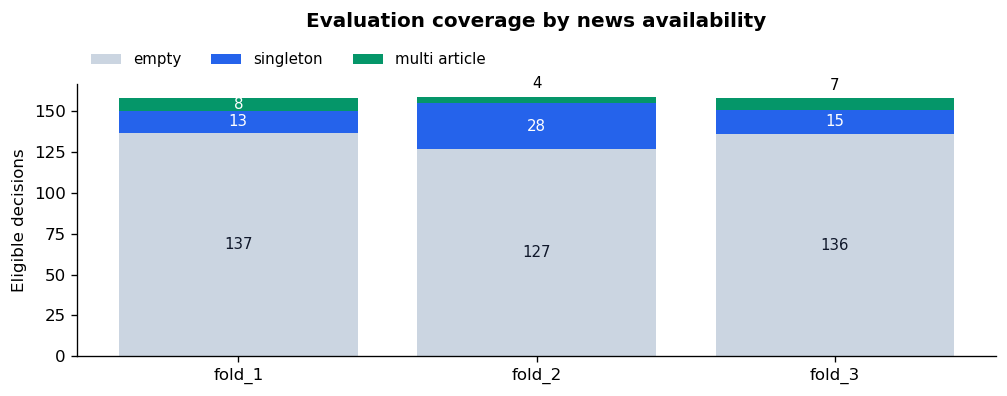

In [9]:
subgroup_rows = []
for run, frame in predictions.groupby("run", sort=False):
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0),
             "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        group = frame.loc[mask]
        scores = score_binary(group.y, group.p_up) if len(group) else {"n": 0, **{m: np.nan for m in METRICS}}
        subgroup_rows.append({"run": run, "group": name, **scores})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## Result bundle

The expandable JSON stores metrics, intervals, per-class/subgroup results, predictions, and provenance inside this notebook. Reuse paired decision dates in later conditions. No sidecar files are written. Test scores must not guide later model or filter choices.

In [10]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "last_direction",
    "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST,
    "hard_prediction_rule": "Repeat sign(log(J_t/J_prev)); zero/missing uses frozen training majority; ties UP",
    "fallback_probability_rule": "Training UP share, estimated on eligible training rows only",
    "log_loss_probability_clip": [1e-15, 1 - 1e-15],
    "probability_rule": "1 for positive latest return; 0 for negative; training UP share for zero/missing. Uncalibrated.",
    "trainable_parameters": 0, "estimated_prior_parameters": 1,
    "input_predictors": ["log_return_t"], "training_seeds": [], "threshold_tuned": False,
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"],
    "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
to_records = lambda frame: json.loads(frame.to_json(orient="records", date_format="iso"))
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "validation_summary": to_records(validation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "intervals": to_records(intervals), "per_class": to_records(per_class),
                 "calibration": to_records(calibration), "subgroups": to_records(subgroups),
                 "predictions": to_records(predictions)}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Saved in notebook output: {len(predictions)} paired predictions; final test evaluated: {RUN_FINAL_TEST}.")

Saved in notebook output: 475 paired predictions; final test evaluated: False.
